
Is oil price movement related to the strength of the US dollar?



Data: FRED DCOILWTICO and DTWEXBGS, January 2015 through January 2025. This is historical analysis. Dependencies: pandas, numpy, matplotlib, seaborn, pandas-datareader, yfinance, statsmodels. Outputs were regenerated from FRED; rerunning requires network access.


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import pandas_datareader as pdr



import statsmodels.api as sm

from datetime import datetime

In [2]:
#pulling data from FRED
start = '2015-01-01'
end = '2025-01-01'

oil = pdr.get_data_fred('DCOILWTICO', start, end, retry_count=1, pause=0.2)
usd = pdr.get_data_fred('DTWEXBGS', start, end, retry_count=1, pause=0.2)

In [3]:
#Merge DataFrames
df = pd.concat([oil, usd], axis=1)
df.columns = ['Oil_Price', 'USD_Index']
#Handle Missing Values
df = df.ffill()
df = df.dropna()
#Resample Weekly
weekly = df.resample('W').mean()
#Calculate Returns
weekly['Oil_Return'] = weekly['Oil_Price'].pct_change() * 100
weekly['USD_Return'] = weekly['USD_Index'].pct_change() * 100
#Lagged Oil Return
weekly['Lag_Oil_Return'] = weekly['Oil_Return'].shift(1)
#Drop Missing Values
weekly = weekly.dropna()

Visualization 1

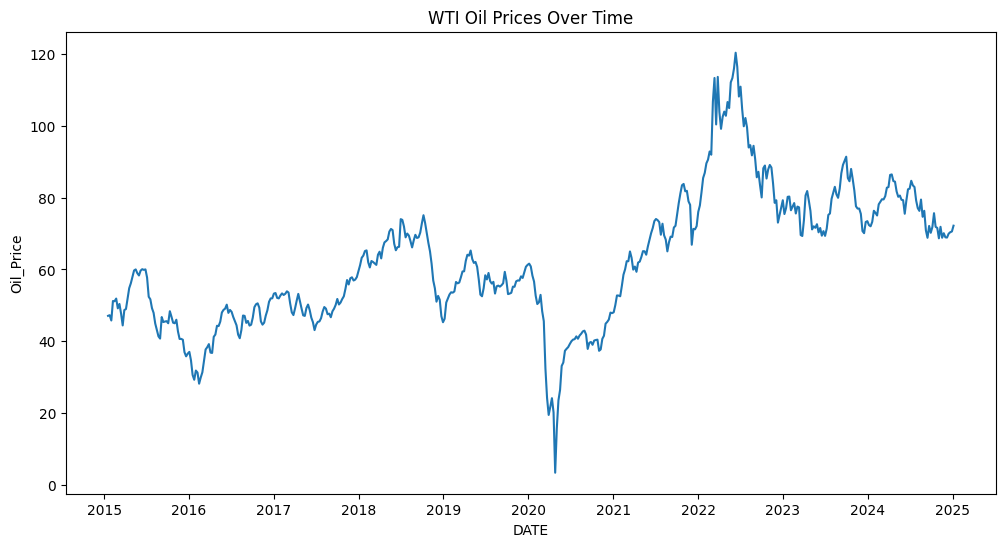

In [4]:
plt.figure(figsize=(12,6))

sns.lineplot(
    data=weekly,
    x=weekly.index,
    y='Oil_Price'
)

plt.title('WTI Oil Prices Over Time')
plt.show()

Visualization 2

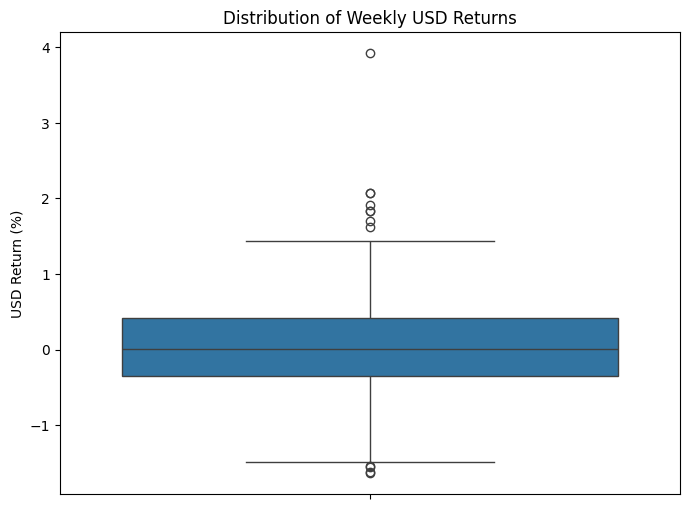

In [5]:
plt.figure(figsize=(8,6))

sns.boxplot(
    y=weekly['USD_Return']
)

plt.title('Distribution of Weekly USD Returns')
plt.ylabel('USD Return (%)')

plt.show()

Visualization 3

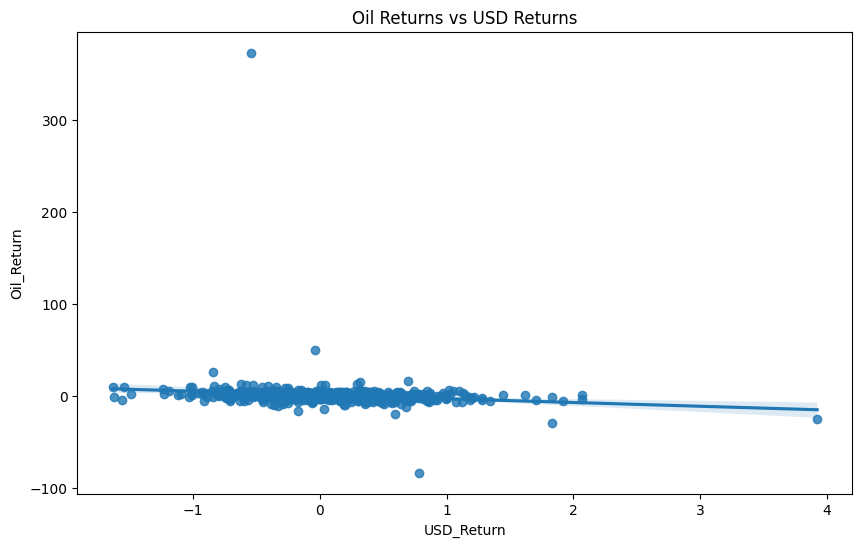

In [6]:
plt.figure(figsize=(10,6))

sns.regplot(
    data=weekly,
    x='USD_Return',
    y='Oil_Return'
)

plt.title('Oil Returns vs USD Returns')
plt.show()

Visualization 4

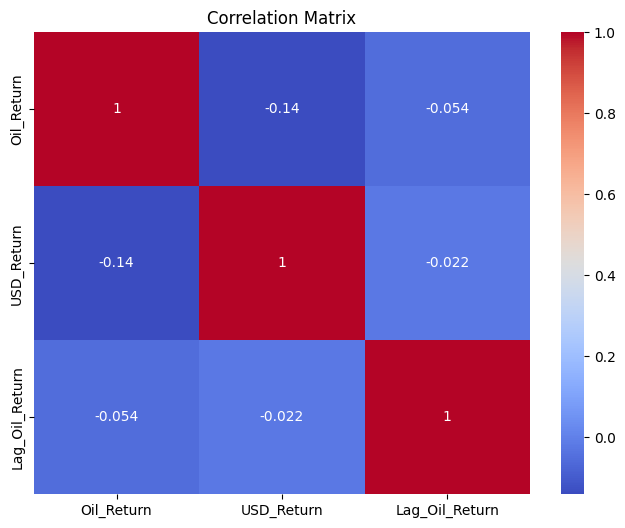

In [7]:
corr = weekly[['Oil_Return','USD_Return','Lag_Oil_Return']].corr()

plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Matrix')
plt.show()

Visualization 5

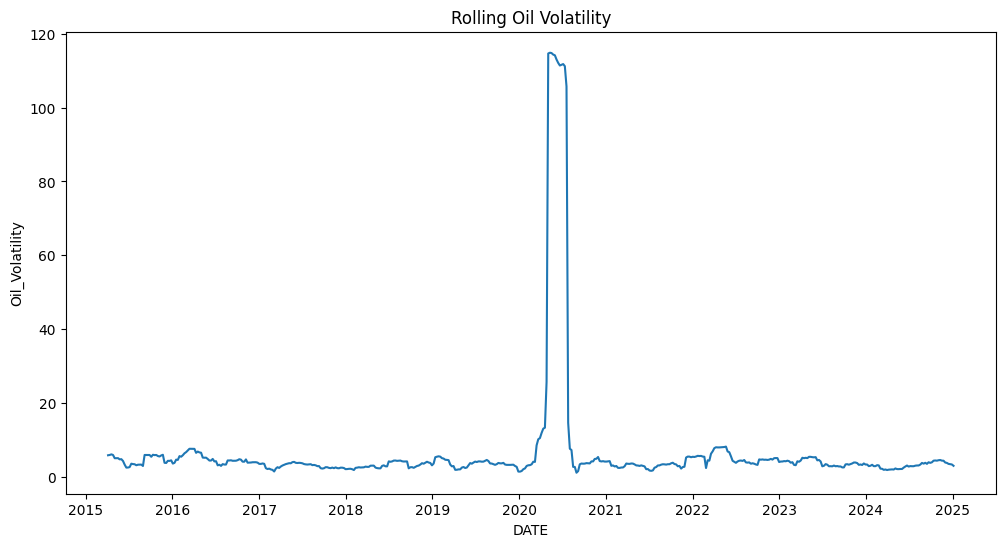

In [8]:
weekly['Oil_Volatility'] = weekly['Oil_Return'].rolling(12).std()

plt.figure(figsize=(12,6))

sns.lineplot(
    data=weekly,
    x=weekly.index,
    y='Oil_Volatility'
)

plt.title('Rolling Oil Volatility')
plt.show()

LS Regression
Business model:

Oil Return=β
0
​
 +β
1
​
 (USD Return)+β
2
​
 (Lagged Oil Return)

**Inline formula visualization:**

Oil Return=β
0
​
 +β
1
​
 (USD Return)+β
2
​
 (Lagged Oil Return)


In [9]:
X = weekly[['USD_Return', 'Lag_Oil_Return']]
y = weekly['Oil_Return']

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             Oil_Return   R-squared:                       0.023
Model:                            OLS   Adj. R-squared:                  0.019
Method:                 Least Squares   F-statistic:                     6.070
Date:                Mon, 26 Oct 2026   Prob (F-statistic):            0.00248
Time:                        00:05:03   Log-Likelihood:                -2224.2
No. Observations:                 521   AIC:                             4454.
Df Residuals:                     518   BIC:                             4467.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              1.0367      0.763      1.

## Interpretation and limits
The saved OLS output uses 521 weekly observations and has R-squared 0.023: the model explains about 2.3% of weekly return variation in-sample. The USD coefficient is negative in this specification. This association is not a causal claim or a trading strategy, and the model does not establish reliable forecasting performance. Inspect residual dependence, outliers, sensitivity to the 2020 negative WTI episode and out-of-sample performance before extending it.
